## Setup: Mounting Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## Verify Dataset Path

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/malnutrition_final"
print("Dataset exists:", os.path.exists(dataset_path))

Dataset exists: True


## List Dataset Contents

In [ ]:
print(os.listdir(dataset_path))

['valid', 'test', 'train', 'data.yaml']


## Check Image and Label Counts for Each Data Split

In [ ]:
for split in ["train", "valid", "test"]:

    image_path = os.path.join(dataset_path, split, "images")
    label_path = os.path.join(dataset_path, split, "labels")

    print("=" * 40)
    print(split.upper())

    print("Images:", len(os.listdir(image_path)))
    print("Labels:", len(os.listdir(label_path)))

TRAIN
Images: 236
Labels: 236
VALID
Images: 48
Labels: 48
TEST
Images: 38
Labels: 38


## Create YOLO Data Configuration File (data.yaml)

In [ ]:
import yaml

data = {
    "path": dataset_path,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 2,
    "names": ["Healthy", "Malnourished"]
}

yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("New data.yaml created!")
print(open(yaml_path).read())

New data.yaml created!
path: /content/drive/MyDrive/malnutrition_final
train: train/images
val: valid/images
test: test/images
nc: 2
names:
- Healthy
- Malnourished



## Install Ultralytics Library

## YOLO Installation

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 10.3 MB/s eta 0:00:00


## Import YOLO Model

In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Load Pre-trained YOLOv8n Model

In [ ]:
model = YOLO("yolov8n.pt")

## Train the YOLOv8 Model

In [ ]:
results = model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    project="/content/malnutrition_training",
    name="yolov8n_malnutrition"
)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/malnutrition_final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_malnutrition, nbs=64, nms=None

## Load the Best Trained Model

In [ ]:
best_model = YOLO(
    "/content/malnutrition_training/yolov8n_malnutrition/weights/best.pt"
)

## Validate the Best Model

In [ ]:
metrics = best_model.val(
    data=yaml_path,
    imgsz=640
)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 37.2±12.8 MB/s, size: 33.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/malnutrition_final/valid/labels.cache... 48 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48 14.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7it/s 1.8s
                   all         48         48      0.936          1      0.992       0.85
               Healthy         24         24      0.917          1       0.99      0.918
          Malnourished         24         24      0.955          1      0.993      0.782
Speed: 7.8ms preprocess, 5.0ms inference, 0.0ms loss, 

## Display Validation Metrics

In [ ]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Precision: 0.9359025506061669
Recall: 1.0
mAP50: 0.9918282051282052
mAP50-95: 0.8504082984077801


## Prepare Test Images for Prediction

In [ ]:
test_image_folder = os.path.join(
    dataset_path,
    "test",
    "images"
)

test_images = [
    os.path.join(test_image_folder, f)
    for f in os.listdir(test_image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of test images:", len(test_images))
print("Example image:", test_images[0])

Number of test images: 38
Example image: /content/drive/MyDrive/malnutrition_final/test/images/underwt-child_jpg.rf.20457cd5d64dd2d4c130f253659b35df.jpg


## Make a Prediction on a Sample Test Image

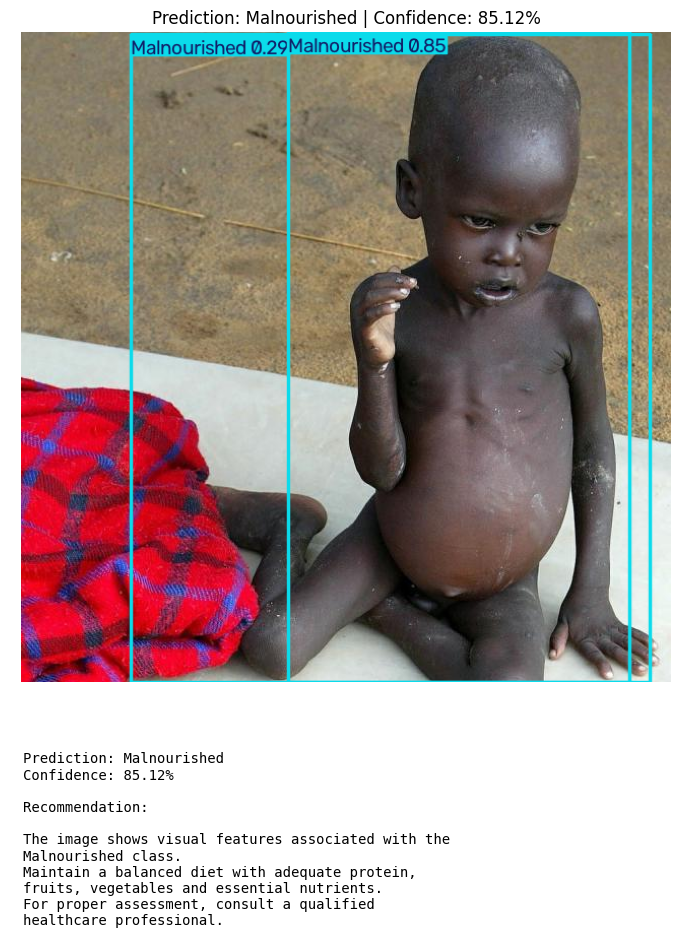

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# -----------------------------
# 1. Select a test image
# -----------------------------
test_image_folder = os.path.join(dataset_path, "test", "images")

test_images = [
    os.path.join(test_image_folder, f)
    for f in os.listdir(test_image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

test_image = random.choice(test_images)

# -----------------------------
# 2. Predict the image
# -----------------------------
prediction = best_model.predict(
    source=test_image,
    conf=0.25,
    verbose=False
)

result = prediction[0]

# -----------------------------
# 3. Get prediction details
# -----------------------------
if len(result.boxes) > 0:

    class_id = int(result.boxes.cls[0])
    predicted_class = best_model.names[class_id]
    confidence = float(result.boxes.conf[0])

    # Create annotated image
    annotated_image = result.plot()

    # Convert BGR to RGB
    annotated_image = annotated_image[:, :, ::-1]

    # -----------------------------
    # 4. Create recommendation
    # -----------------------------
    if predicted_class == "Malnourished":
        recommendation = (
            "Recommendation:\n\n"
            "The image shows visual features associated with the\n"
            "Malnourished class.\n"
            "Maintain a balanced diet with adequate protein,\n"
            "fruits, vegetables and essential nutrients.\n"
            "For proper assessment, consult a qualified\n"
            "healthcare professional."
        )

    else:
        recommendation = (
            "Recommendation:\n\n"
            "The image is classified as Healthy.\n"
            "Continue maintaining a balanced and nutritious diet."
        )

    # -----------------------------
    # 5. Create one combined image
    # -----------------------------
    fig = plt.figure(figsize=(8, 10))

    # Image area
    ax1 = fig.add_axes([0.08, 0.30, 0.84, 0.65])
    ax1.imshow(annotated_image)
    ax1.axis("off")

    # Title
    ax1.set_title(
        f"Prediction: {predicted_class} | "
        f"Confidence: {confidence * 100:.2f}%",
        fontsize=12
    )

    # Recommendation area
    ax2 = fig.add_axes([0.08, 0.05, 0.84, 0.20])
    ax2.set_facecolor("black")
    ax2.axis("off")

    ax2.text(
        0.02,
        0.90,
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%\n\n"
        f"{recommendation}",
        color="black",
        fontsize=10,
        verticalalignment="top",
        fontfamily="monospace"
    )


    plt.show()

else:
    print("No detection was made for this image.")

# Evaluation on the complete test dataset

In [ ]:
# ============================================
# FINAL TEST SET EVALUATION
# ============================================

test_metrics = best_model.val(
    data=yaml_path,
    split="test",
    imgsz=640,
    plots=True,
    verbose=True
)

# Extract test metrics
test_precision = float(test_metrics.box.mp)
test_recall = float(test_metrics.box.mr)
test_map50 = float(test_metrics.box.map50)
test_map5095 = float(test_metrics.box.map)

# Calculate F1-score
if test_precision + test_recall > 0:
    test_f1 = (
        2 * test_precision * test_recall
        / (test_precision + test_recall)
    )
else:
    test_f1 = 0.0

print("\n========================================")
print("       FINAL TEST SET RESULTS")
print("========================================")

print(f"Precision   : {test_precision:.4f}")
print(f"Recall      : {test_recall:.4f}")
print(f"F1-score    : {test_f1:.4f}")
print(f"mAP@50      : {test_map50:.4f}")
print(f"mAP@50-95   : {test_map5095:.4f}")

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 39.4±12.5 MB/s, size: 37.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/malnutrition_final/test/labels.cache... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 12.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.6s
                   all         38         38      0.956      0.961      0.991      0.809
               Healthy         19         19      0.913          1      0.995      0.901
          Malnourished         19         19          1      0.922      0.986      0.718
Speed: 8.3ms preprocess, 5.1ms inference, 0.0ms loss, 2

# Accuracy and Confusion matrix

In [ ]:
# ============================================
# IMAGE-LEVEL ACCURACY + CONFUSION MATRIX
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# Class names
class_names = ["Healthy", "Malnourished"]

# Test folders
test_image_folder = os.path.join(
    dataset_path, "test", "images"
)

test_label_folder = os.path.join(
    dataset_path, "test", "labels"
)

# Get test images
test_images = [
    os.path.join(test_image_folder, f)
    for f in os.listdir(test_image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

test_images.sort()

# Store actual and predicted classes
actual_classes = []
predicted_classes = []

# Store image names
image_names = []

# ============================================
# Process every test image
# ============================================

for image_path in test_images:

    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    label_path = os.path.join(
        test_label_folder,
        image_name + ".txt"
    )

    # ----------------------------------------
    # Read ground-truth class
    # ----------------------------------------

    with open(label_path, "r") as f:
        lines = f.readlines()

    # Current dataset has one labeled object per image
    true_class = int(lines[0].split()[0])

    # ----------------------------------------
    # Predict image
    # ----------------------------------------

    result = best_model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )[0]

    # ----------------------------------------
    # Get highest-confidence prediction
    # ----------------------------------------

    if len(result.boxes) > 0:

        confidences = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy()

        best_index = np.argmax(confidences)

        predicted_class = int(classes[best_index])

    else:

        # 2 = No Detection
        predicted_class = 2

    # ----------------------------------------
    # Store results
    # ----------------------------------------

    actual_classes.append(true_class)
    predicted_classes.append(predicted_class)
    image_names.append(image_name)


# ============================================
# Calculate Accuracy
# ============================================

actual_classes = np.array(actual_classes)
predicted_classes = np.array(predicted_classes)

correct_predictions = np.sum(
    actual_classes == predicted_classes
)

total_images = len(actual_classes)

accuracy = correct_predictions / total_images

print("\n========================================")
print("       IMAGE-LEVEL TEST ACCURACY")
print("========================================")

print(f"Correct predictions : {correct_predictions}")
print(f"Total test images   : {total_images}")
print(f"Accuracy            : {accuracy:.4f}")
print(f"Accuracy (%)        : {accuracy * 100:.2f}%")


       IMAGE-LEVEL TEST ACCURACY
Correct predictions : 36
Total test images   : 38
Accuracy            : 0.9474
Accuracy (%)        : 94.74%



Confusion Matrix:
[[19  0  0]
 [ 2 17  0]
 [ 0  0  0]]


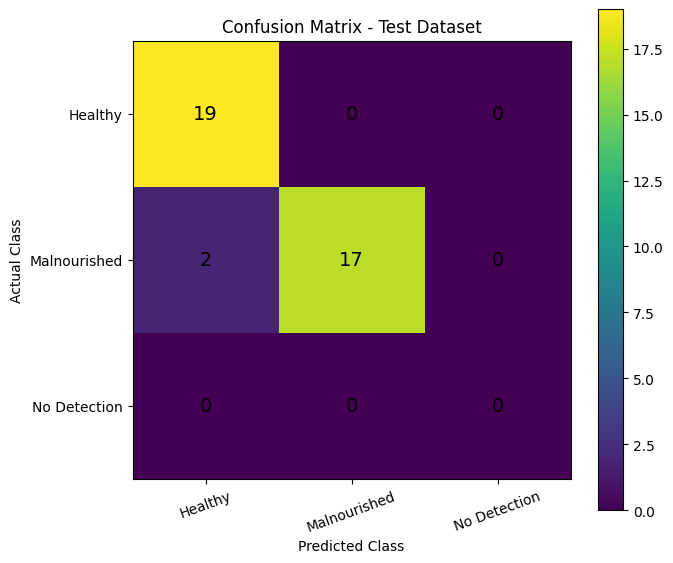

In [ ]:
# ============================================
# CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    actual_classes,
    predicted_classes,
    labels=[0, 1, 2]
)

display_names = [
    "Healthy",
    "Malnourished",
    "No Detection"
]

print("\nConfusion Matrix:")
print(cm)

# ============================================
# Plot confusion matrix
# ============================================

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title("Confusion Matrix - Test Dataset")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(display_names)),
    display_names,
    rotation=20
)

plt.yticks(
    range(len(display_names)),
    display_names
)

# Display values inside cells
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

# Classification Report

In [ ]:
# ============================================
# CLASSIFICATION REPORT
# ============================================

# Only evaluate detected predictions
# No Detection is handled separately

detected_mask = predicted_classes != 2

actual_detected = actual_classes[detected_mask]
predicted_detected = predicted_classes[detected_mask]

print("\n========================================")
print("       CLASSIFICATION REPORT")
print("========================================")

print(
    classification_report(
        actual_detected,
        predicted_detected,
        labels=[0, 1],
        target_names=["Healthy", "Malnourished"],
        zero_division=0
    )
)


       CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy       0.90      1.00      0.95        19
Malnourished       1.00      0.89      0.94        19

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38



# Save the final trained Model

In [ ]:
# ============================================
# SAVE FINAL TRAINED MODEL
# ============================================

import os
import shutil

# Original best model
best_model_path = (
    "/content/malnutrition_training/"
    "yolov8n_malnutrition/weights/best.pt"
)

# Create final model folder
final_model_folder = (
    "/content/drive/MyDrive/malnutrition_final_model"
)

os.makedirs(
    final_model_folder,
    exist_ok=True
)

# Final model path
final_model_path = os.path.join(
    final_model_folder,
    "best_malnutrition_yolov8n.pt"
)

# Copy best model
shutil.copy2(
    best_model_path,
    final_model_path
)

print("========================================")
print("       FINAL MODEL SAVED")
print("========================================")

print("Model location:")
print(final_model_path)

       FINAL MODEL SAVED
Model location:
/content/drive/MyDrive/malnutrition_final_model/best_malnutrition_yolov8n.pt


# Verify the model

In [ ]:
# ============================================
# VERIFY FINAL MODEL
# ============================================

from ultralytics import YOLO

final_model = YOLO(final_model_path)

print("Final model loaded successfully!")
print("Classes:", final_model.names)

Final model loaded successfully!
Classes: {0: 'Healthy', 1: 'Malnourished'}


In [ ]:
from google.colab import files

files.download(final_model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>